# Option 2: Logistic Regression
## Step 0: Import Libraries & Load Data

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RANDOM_STATE = 27

In [ ]:
data_path = "./data"
train_df = pd.read_csv(f"{data_path}/train.csv")
test_df = pd.read_csv(f"{data_path}/test.csv")

## Step 1: Split the Training Data

In [64]:
from sklearn.model_selection import train_test_split

X = train_df.drop(columns=["label"])
y = train_df["label"]
X_train, X_dev, y_train, y_dev = train_test_split(X, y, test_size=2000, random_state=RANDOM_STATE, stratify=y)
X_dev[["id"]].to_csv("val_ids.csv", index=False)
print(len(X_train), len(X_dev))

8000 2000


In [65]:
# Sample a few examples of each class to see what the data looks like
for label in [0, 1]:
    print(f"===== label {label} ({'AI' if label else 'human'}) =====")
    for t in X_train[y_train == label]["text"].sample(3, random_state=RANDOM_STATE):
        print(t[:400], "\n")

===== label 0 (human) =====
Crystalline Fe3O4/NiO bilayers were grown on MgO(001) substrates using
reactive molecular beam epitaxy to investigate their structural properties and
their morphology. The film thickness either of the Fe3O4 film or of the NiO
film has been varied to shed light on the relaxation of the bilayer system. The
surface properties as studied by x-ray photo electron spectroscopy and low
energy electron dif 

8 ounces whole-grain medium shell pasta
4 plum tomatoes, halved lengthwise
2 tablespoons whole wheat breadcrumbs
1 teaspoon plus 1 tablespoon olive oil
1/2 teaspoon Italian seasoning
1 tablespoon all-purpose flour
1 clove garlic, minced
1/2 cup canned pumpkin puree
One 12-ounce can nonfat evaporated milk
1/2 cup reduced-fat shredded Cheddar
1/2 cup part-skim mozzarella
1/4 cup grated Parmesan
Kosh 

Upgraded electronics, improved water system dynamics, better calibration and
analysis techniques allowed Super-Kamiokande-IV to clearly observe very
low-energy 8B sol

## Step 2: Vectorize Data

In [66]:
from sklearn.feature_extraction.text import TfidfVectorizer

train_text = X_train["text"]  # TfidfVectorizer still lowercases and drops punctuation by default
dev_text = X_dev["text"]

M = 2
vectorizer = TfidfVectorizer(min_df=M, ngram_range=(1, 2), sublinear_tf=True)
X_train_tfidf = vectorizer.fit_transform(train_text)  # learn vocabulary + IDF from training text only
X_dev_tfidf = vectorizer.transform(dev_text)          # reuse them on validation
print(X_train_tfidf.shape, X_dev_tfidf.shape)

(8000, 167660) (2000, 167660)


## Step 3: Logistic Regression

### Evaluate Functions

In [67]:
# Import logistic regression model from sklearn
import time

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score


def evaluate(model, X_tra, y_tra, X_va, y_va):
    """
    Fit a classifier and evaluate it on the training and validation sets.

    Parameters:
    - model: sklearn classifier with a predict_proba method.
    - X_tra, y_tra: training features and labels.
    - X_va, y_va: validation features and labels.
    ...

    Returns:
    - res: dictionary, containing training AUROC, validation AUROC, and training time.
    """
    start = time.perf_counter()
    model.fit(X_tra, y_tra)
    train_time = time.perf_counter() - start

    train_auroc = roc_auc_score(y_tra, model.predict_proba(X_tra)[:, 1])
    val_auroc = roc_auc_score(y_va, model.predict_proba(X_va)[:, 1])
    print(f"Train AUROC: {train_auroc:.4f} | Val AUROC: {val_auroc:.4f} | Time: {train_time:.1f}s")
    res = {"train_auroc": train_auroc, "val_auroc": val_auroc, "train_time": train_time}
    return res

def run_c_grid(penalty, X_tr, y_tr, X_va, y_va, C_values):
    """
    Train logistic regression at each C value and collect the results.

    Parameters:
    - penalty: str, either "L1" or "L2" to specify the regularization type.
    - X_tr, y_tr: training features and labels.
    - X_va, y_va: validation features and labels.
    - C_values: iterable of floats, C values to try (inverse regularization strength).

    Returns:
    - results_df: pd.DataFrame, one row per (penalty, C) with train/validation
      AUROC, train time, and the number of nonzero weights.
    """
    results = []
    for C in C_values:
        if penalty == "L1":
            model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                                        l1_ratio=1.0, solver="liblinear", C=C)
        else:
            model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                                        l1_ratio=0, C=C)

        print(f"{penalty}, C={C:g}: ", end="")
        res = evaluate(model, X_tr, y_tr, X_va, y_va)
        res.update({"penalty": penalty, "C": C,
                    "nonzero_weights": int((model.coef_ != 0).sum())})
        results.append(res)

    return pd.DataFrame(results)


C_values = np.logspace(-2, 3, 6)  # 0.01, 0.1, 1, 10, 100, 1000


### No Regularization Model

In [68]:
model_noreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, C=np.inf)
noreg_res = evaluate(model_noreg, X_train_tfidf, y_train, X_dev_tfidf, y_dev)


Train AUROC: 1.0000 | Val AUROC: 0.9402 | Time: 0.3s


### L1 Regularization Model

In [69]:
l1_grid = run_c_grid("L1", X_train_tfidf, y_train, X_dev_tfidf, y_dev, C_values)
l1_grid

L1, C=0.01: Train AUROC: 0.5000 | Val AUROC: 0.5000 | Time: 0.1s
L1, C=0.1: Train AUROC: 0.6734 | Val AUROC: 0.6674 | Time: 0.9s
L1, C=1: Train AUROC: 0.9172 | Val AUROC: 0.9011 | Time: 0.7s
L1, C=10: Train AUROC: 0.9999 | Val AUROC: 0.9323 | Time: 1.7s
L1, C=100: Train AUROC: 1.0000 | Val AUROC: 0.9273 | Time: 1.4s
L1, C=1000: Train AUROC: 1.0000 | Val AUROC: 0.9256 | Time: 0.5s


,train_auroc,val_auroc,train_time,penalty,C,nonzero_weights
0,0.500000,0.500000,0.113717,L1,0.01,0
1,0.673364,0.667446,0.923164,L1,0.10,2
2,0.917195,0.901085,0.742268,L1,1.00,189
3,0.999944,0.932325,1.651057,L1,10.00,2075
4,1.000000,0.927340,1.429067,L1,100.00,2838
5,1.000000,0.925641,0.475123,L1,1000.00,5296


### L2 Regularization Model

In [70]:
l2_grid = run_c_grid("L2", X_train_tfidf, y_train, X_dev_tfidf, y_dev, C_values)
l2_grid

L2, C=0.01: Train AUROC: 0.9441 | Val AUROC: 0.8804 | Time: 0.1s
L2, C=0.1: Train AUROC: 0.9648 | Val AUROC: 0.9006 | Time: 0.1s
L2, C=1: Train AUROC: 0.9957 | Val AUROC: 0.9306 | Time: 0.2s
L2, C=10: Train AUROC: 1.0000 | Val AUROC: 0.9421 | Time: 0.3s
L2, C=100: Train AUROC: 1.0000 | Val AUROC: 0.9430 | Time: 0.3s
L2, C=1000: Train AUROC: 1.0000 | Val AUROC: 0.9389 | Time: 0.2s


,train_auroc,val_auroc,train_time,penalty,C,nonzero_weights
0,0.944129,0.880379,0.057378,L2,0.01,167660
1,0.964781,0.900648,0.088209,L2,0.10,167660
2,0.995660,0.930601,0.158689,L2,1.00,167660
3,1.000000,0.942142,0.271791,L2,10.00,167660
4,1.000000,0.943037,0.301002,L2,100.00,167660
5,1.000000,0.938888,0.181104,L2,1000.00,167660


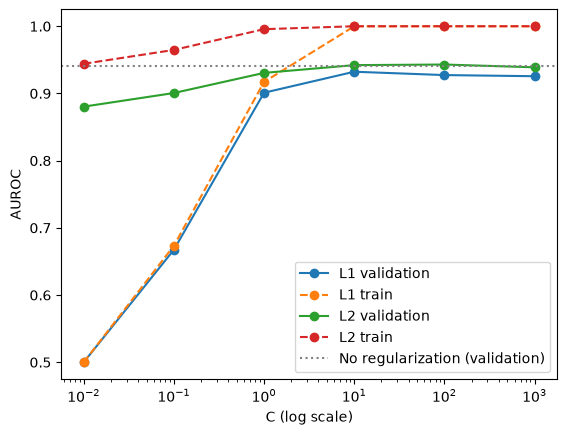

In [71]:
grid_df = {
    "L1": l1_grid,
    "L2": l2_grid
}

for penalty in ["L1", "L2"]:
    sub = grid_df[penalty]
    plt.plot(sub["C"], sub["val_auroc"], marker="o", label=f"{penalty} validation")
    plt.plot(sub["C"], sub["train_auroc"], marker="o", linestyle="--", label=f"{penalty} train")

plt.axhline(noreg_res["val_auroc"], color="gray", linestyle=":", label="No regularization (validation)")
plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("AUROC")
plt.legend()
plt.show()

### Naive Bayes

In [72]:
from sklearn.naive_bayes import MultinomialNB


def run_alpha_grid(X_tr, y_tr, X_va, y_va, alpha_values):
    """
    Train Multinomial Naive Bayes at each smoothing value alpha and collect the results.

    Parameters:
    - X_tr, y_tr: training features and labels.
    - X_va, y_va: validation features and labels.
    - alpha_values: iterable of floats, smoothing pseudo-counts to try.

    Returns:
    - results_df: pd.DataFrame, one row per alpha with train/validation AUROC and train time.
    """
    results = []
    for alpha in alpha_values:
        model = MultinomialNB(alpha=alpha)
        print(f"alpha={alpha:g}: ", end="")
        res = evaluate(model, X_tr, y_tr, X_va, y_va)
        res["alpha"] = alpha
        results.append(res)
    return pd.DataFrame(results)


alpha_values = np.logspace(-3, 1, 5)  # 0.001, 0.01, 0.1, 1, 10
nb_df = run_alpha_grid(X_train_tfidf, y_train, X_dev_tfidf, y_dev, alpha_values)
nb_df

alpha=0.001: Train AUROC: 1.0000 | Val AUROC: 0.8792 | Time: 0.0s
alpha=0.01: Train AUROC: 1.0000 | Val AUROC: 0.8869 | Time: 0.0s
alpha=0.1: Train AUROC: 0.9998 | Val AUROC: 0.8934 | Time: 0.0s
alpha=1: Train AUROC: 0.9932 | Val AUROC: 0.8931 | Time: 0.0s
alpha=10: Train AUROC: 0.9672 | Val AUROC: 0.8839 | Time: 0.0s


,train_auroc,val_auroc,train_time,alpha
0,1.000000,0.879156,0.010992,0.001
1,0.999999,0.886872,0.008202,0.010
2,0.999776,0.893431,0.007055,0.100
3,0.993214,0.893120,0.007908,1.000
4,0.967242,0.883932,0.007543,10.000


## Step 4: Run Predictions on Test Data

In [73]:
# 1. Refit vectorizer + model on all 10,000 labeled rows
final_vectorizer = TfidfVectorizer(min_df=M, ngram_range=(1, 2), sublinear_tf=True)
X_full = final_vectorizer.fit_transform(train_df["text"])
X_test = final_vectorizer.transform(test_df["text"])  # transform only, never fit on test

final_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, l1_ratio=0, C=100)
final_model.fit(X_full, train_df["label"])

# 2. Predict P(AI) for each test passage
submission = pd.DataFrame({
    "id": test_df["id"],
    "label": final_model.predict_proba(X_test)[:, 1],
})

# 3. Match the row order of sample_submission.csv
sample_submission = pd.read_csv(f"{data_path}/sample_submission.csv")
submission = submission.set_index("id").loc[sample_submission["id"]].reset_index()

# 4. Sanity checks before uploading
assert list(submission.columns) == ["id", "label"]
assert len(submission) == 3000 and submission["id"].is_unique
assert set(submission["id"]) == set(test_df["id"])
assert submission["label"].between(0, 1).all()

submission.to_csv("submission_lr.csv", index=False)
print("Saved 3,000 test predictions to submission_lr.csv")

Saved 3,000 test predictions to submission_lr.csv
